# Adam 优化算法训练卷积神经网络的数值稳定性与超参数敏感性研究

## 摘要

 本实验以手写数字图像分类为任务，使用小型卷积神经网络，考察 Adam 优化算法的收敛表现、数值稳定性及超参数敏感性。通过与带动量 SGD 对照，并改变学习率、一阶矩系数 beta1、二阶矩系数 beta2 和稳定项 epsilon，记录训练/验证损失、准确率和梯度范数。实验结果由下方代码实际运行生成，避免预设结论。
 

## 1. 问题背景

卷积神经网络（CNN）广泛用于图像分类。训练过程需要通过反向传播得到损失函数对网络参数的梯度，再由优化算法逐步更新参数。学习率过大可能造成损失振荡或发散，学习率过小则会使训练缓慢；梯度尺度差异也会使统一步长难以适配所有参数。
Adam 使用梯度的一阶、二阶指数移动平均构造参数自适应更新，因此适合作为本研究对象。本文的问题是：Adam 的超参数如何影响 CNN 训练的收敛过程和数值稳定表现？

## 2. 核心算法

网络使用交叉熵损失。每个小批量先执行前向传播得到预测及损失，再通过反向传播计算梯度，最后由优化器更新参数。Adam 对参数 theta 的更新为：

$$g_t = \nabla_\theta L_t$$

$$m_t = \beta_1 m_{t-1} + (1-\beta_1) g_t$$

$$v_t = \beta_2 v_{t-1} + (1-\beta_2) g_t^2$$

$$\hat{m}_t = \frac{m_t}{1-\beta_1^t}$$

$$\hat{v}_t = \frac{v_t}{1-\beta_2^t}$$

$$\theta_{t+1} = \theta_t - \alpha \frac{\hat{m}_t}{\sqrt{\hat{v}_t}+\epsilon}$$


$$
\begin{aligned}
&\alpha \text{：学习率} \\
&\beta_1,\beta_2 \text{：分别控制梯度、平方梯度的历史平滑程度} \\
&\epsilon \text{：防止分母趋近于0，保证数值稳定性}
\end{aligned}
$$
反向传播负责计算梯度；Adam 负责根据梯度历史计算参数更新量。

## 3. 理论分析

对光滑且凸的目标函数，在适当步长等条件下，梯度法可以收敛到全局极小点；但 CNN 的训练目标通常非凸，因此本实验不声称 Adam 必然收敛到全局最优，而通过有限迭代下的损失曲线、验证准确率与梯度范数观察其经验收敛行为。

数值稳定性主要从两方面考察：一是损失或梯度是否出现剧烈波动；二是梯度范数是否出现异常增大。$\epsilon$ 对更新分母提供下界，降低极小二阶矩导致更新量过大的风险。

超参数实验采用控制变量法，每组只改变一个参数并保持模型结构、数据划分和随机种子一致。

## 4. 编程实践

下方代码依次完成数据准备、CNN 定义、训练与评估、优化器对照、超参数实验和结果导出。
使用 sklearn 内置 Digits 数据集（$8\times8$ 图像），无需联网下载；数据划分为训练、验证、测试集。


## 5. 数值结果

运行后将自动绘制训练曲线，并在末尾输出测试集指标汇总表、保存 CSV。请结合实际输出比较不同参数下的收敛速度、波动和泛化表现；不要在运行前填写未经计算的数值结论。

数据集：scikit-learn 自带的 Digits（$8\times8$ 灰度手写数字），不需要下载。

依赖：numpy、matplotlib、pandas、scikit-learn、torch。


In [1]:
# %% 1. 导入库与实验配置
from __future__ import annotations

import copy
import random
from pathlib import Path
from typing import Callable

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
from sklearn.datasets import load_digits
from sklearn.model_selection import train_test_split
from torch.utils.data import DataLoader, TensorDataset

SEED = 2026
EPOCHS = 18
BATCH_SIZE = 64
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")

# 结果统一保存到项目根目录下的“实验结果”文件夹
ROOT = Path.cwd().parent if Path.cwd().name == "代码" else Path.cwd()
OUT_DIR = ROOT / "实验结果" / "图表" / "初版实验"
DATA_DIR = ROOT / "实验结果" / "数据表" / "初版实验"
OUT_DIR.mkdir(parents=True, exist_ok=True)
DATA_DIR.mkdir(parents=True, exist_ok=True)


def set_seed(seed: int = SEED) -> None:
    """固定随机性，使不同优化器实验可比较。"""
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)


set_seed()
print(f"Device: {DEVICE}")

Device: cpu


In [2]:
# %% 2. 数据准备：Digits 图像分类
digits = load_digits()
X = (digits.images / 16.0).astype(np.float32)  # 像素归一化到 [0, 1]
y = digits.target.astype(np.int64)

# 训练 / 验证 / 测试 = 70% / 15% / 15%
X_train, X_temp, y_train, y_temp = train_test_split(
    X, y, test_size=0.30, random_state=SEED, stratify=y
)
X_val, X_test, y_val, y_test = train_test_split(
    X_temp, y_temp, test_size=0.50, random_state=SEED, stratify=y_temp
)


def make_loader(images: np.ndarray, labels: np.ndarray, shuffle: bool) -> DataLoader:
    images_t = torch.from_numpy(images).unsqueeze(1)  # N, 1, 8, 8
    labels_t = torch.from_numpy(labels)
    dataset = TensorDataset(images_t, labels_t)
    generator = torch.Generator().manual_seed(SEED)
    return DataLoader(dataset, batch_size=BATCH_SIZE, shuffle=shuffle, generator=generator)


train_loader = make_loader(X_train, y_train, shuffle=True)
val_loader = make_loader(X_val, y_val, shuffle=False)
test_loader = make_loader(X_test, y_test, shuffle=False)
print(f"训练集: {len(X_train)}，验证集: {len(X_val)}，测试集: {len(X_test)}")

训练集: 1257，验证集: 270，测试集: 270


In [3]:
# %% 3. 小型 CNN：固定网络结构，仅改变优化算法或超参数
class SmallCNN(nn.Module):
    def __init__(self) -> None:
        super().__init__()
        self.features = nn.Sequential(
            nn.Conv2d(1, 8, kernel_size=3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(kernel_size=2),
            nn.Conv2d(8, 16, kernel_size=3, padding=1),
            nn.ReLU(),
        )
        self.classifier = nn.Sequential(
            nn.Flatten(),
            nn.Linear(16 * 4 * 4, 32),
            nn.ReLU(),
            nn.Linear(32, 10),
        )

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        return self.classifier(self.features(x))


def evaluate(model: nn.Module, loader: DataLoader, criterion: nn.Module) -> tuple[float, float]:
    """返回平均损失和准确率。"""
    model.eval()
    total_loss = 0.0
    total_correct = 0
    total = 0
    with torch.no_grad():
        for x_batch, y_batch in loader:
            x_batch, y_batch = x_batch.to(DEVICE), y_batch.to(DEVICE)
            logits = model(x_batch)
            total_loss += criterion(logits, y_batch).item() * y_batch.size(0)
            total_correct += (logits.argmax(dim=1) == y_batch).sum().item()
            total += y_batch.size(0)
    return total_loss / total, total_correct / total


def train_experiment(
    label: str,
    optimizer_factory: Callable[[list], torch.optim.Optimizer],
    epochs: int = EPOCHS,
) -> dict:
    """在相同初值下训练一次，并记录数值行为。"""
    set_seed()
    model = SmallCNN().to(DEVICE)
    initial_state = copy.deepcopy(model.state_dict())
    model.load_state_dict(initial_state)
    criterion = nn.CrossEntropyLoss()
    optimizer = optimizer_factory(model.parameters())
    history = {"epoch": [], "train_loss": [], "val_loss": [], "val_acc": [], "grad_norm": []}

    for epoch in range(1, epochs + 1):
        model.train()
        loss_sum = 0.0
        samples = 0
        grad_norm_sum = 0.0
        batches = 0

        for x_batch, y_batch in train_loader:
            x_batch, y_batch = x_batch.to(DEVICE), y_batch.to(DEVICE)
            optimizer.zero_grad()
            logits = model(x_batch)
            loss = criterion(logits, y_batch)
            loss.backward()

            # 梯度二范数：观察是否有明显的梯度爆炸或极小梯度。
            squared_norm = sum(
                parameter.grad.detach().pow(2).sum().item()
                for parameter in model.parameters()
                if parameter.grad is not None
            )
            grad_norm_sum += squared_norm ** 0.5
            batches += 1
            optimizer.step()
            loss_sum += loss.item() * y_batch.size(0)
            samples += y_batch.size(0)

        val_loss, val_acc = evaluate(model, val_loader, criterion)
        history["epoch"].append(epoch)
        history["train_loss"].append(loss_sum / samples)
        history["val_loss"].append(val_loss)
        history["val_acc"].append(val_acc)
        history["grad_norm"].append(grad_norm_sum / batches)

    test_loss, test_acc = evaluate(model, test_loader, criterion)
    result = {
        "label": label,
        "history": pd.DataFrame(history),
        "test_loss": test_loss,
        "test_acc": test_acc,
    }
    print(f"{label:<22} 测试损失={test_loss:.4f}, 测试准确率={test_acc:.4f}")
    return result


SGD (lr=0.02)          测试损失=0.1129, 测试准确率=0.9630
Adam (lr=0.001)        测试损失=0.1689, 测试准确率=0.9519


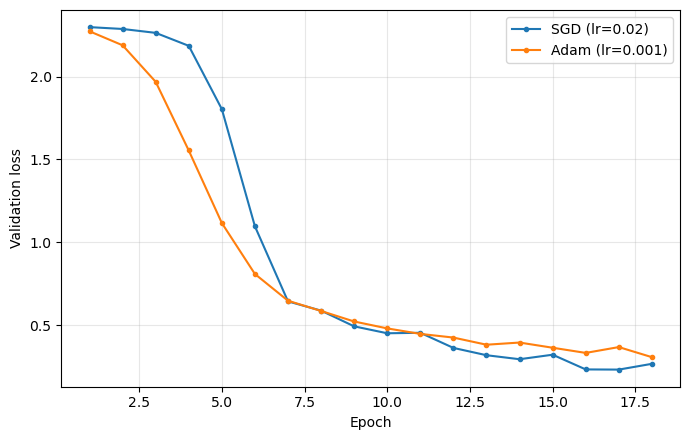

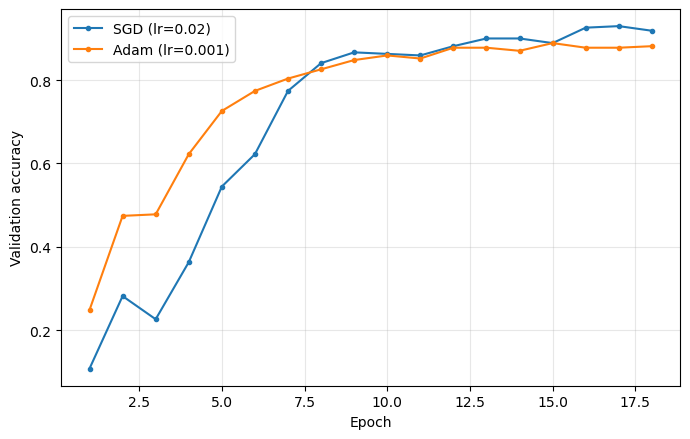

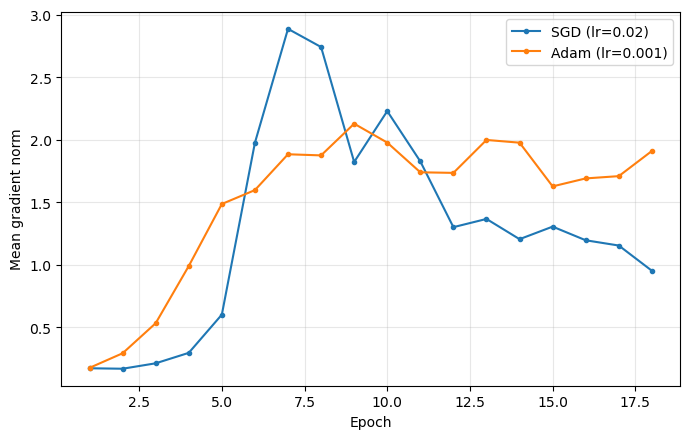

In [4]:
# %% 4. 基线实验：SGD 与 Adam 的比较
# 对照组采用动量 SGD；Adam 使用 PyTorch 的默认 beta1、beta2 和 epsilon。
baseline_results = []
baseline_results.append(
    train_experiment("SGD (lr=0.02)", lambda p: torch.optim.SGD(p, lr=0.02, momentum=0.9))
)
baseline_results.append(
    train_experiment("Adam (lr=0.001)", lambda p: torch.optim.Adam(p, lr=0.001))
)


def plot_histories(results: list[dict], value: str, ylabel: str, filename: str) -> None:
    plt.figure(figsize=(7, 4.5))
    for result in results:
        history = result["history"]
        plt.plot(history["epoch"], history[value], marker="o", markersize=3, label=result["label"])
    plt.xlabel("Epoch")
    plt.ylabel(ylabel)
    plt.grid(alpha=0.3)
    plt.legend()
    plt.tight_layout()
    plt.savefig(OUT_DIR / filename, dpi=180)
    plt.show()


plot_histories(baseline_results, "val_loss", "Validation loss", "01_sgd_adam_loss.png")
plot_histories(baseline_results, "val_acc", "Validation accuracy", "02_sgd_adam_accuracy.png")
plot_histories(baseline_results, "grad_norm", "Mean gradient norm", "03_sgd_adam_gradient_norm.png")


Adam (lr=0.0001)       测试损失=1.9915, 测试准确率=0.5704
Adam (lr=0.001)        测试损失=0.1584, 测试准确率=0.9593
Adam (lr=0.01)         测试损失=0.0841, 测试准确率=0.9778


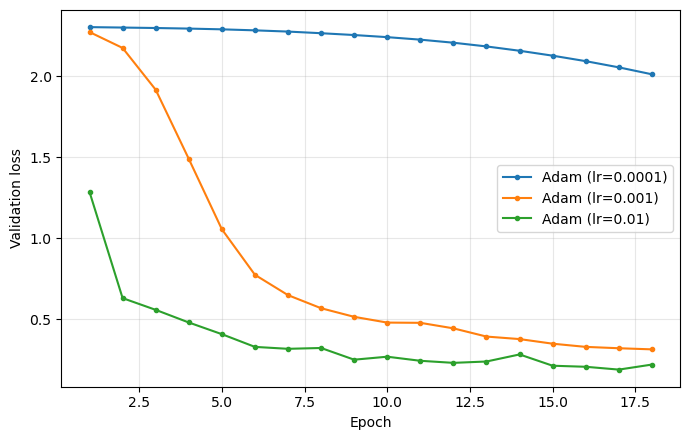

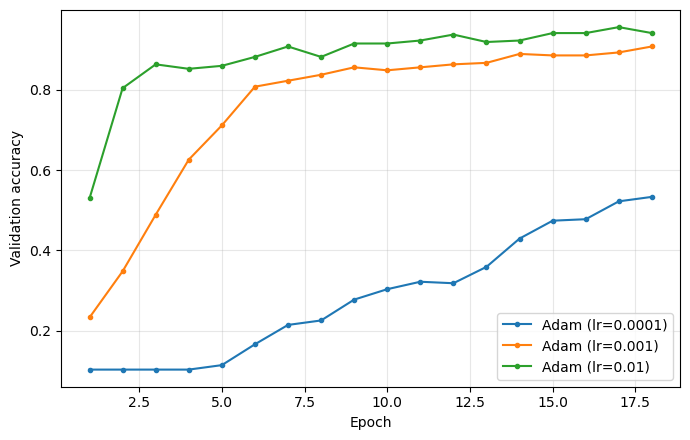

In [5]:
# %% 5. 学习率 alpha 敏感性
# 预测现象：alpha 过小收敛慢；适中时收敛快；过大时损失会震荡或变差。
lr_results = []
for lr in [1e-4, 1e-3, 1e-2]:
    lr_results.append(
        train_experiment(f"Adam (lr={lr:g})", lambda p, lr=lr: torch.optim.Adam(p, lr=lr))
    )
plot_histories(lr_results, "val_loss", "Validation loss", "04_learning_rate_loss.png")
plot_histories(lr_results, "val_acc", "Validation accuracy", "05_learning_rate_accuracy.png")

Adam (beta1=0.5)       测试损失=0.1593, 测试准确率=0.9556
Adam (beta1=0.9)       测试损失=0.1411, 测试准确率=0.9630
Adam (beta1=0.99)      测试损失=0.2202, 测试准确率=0.9296


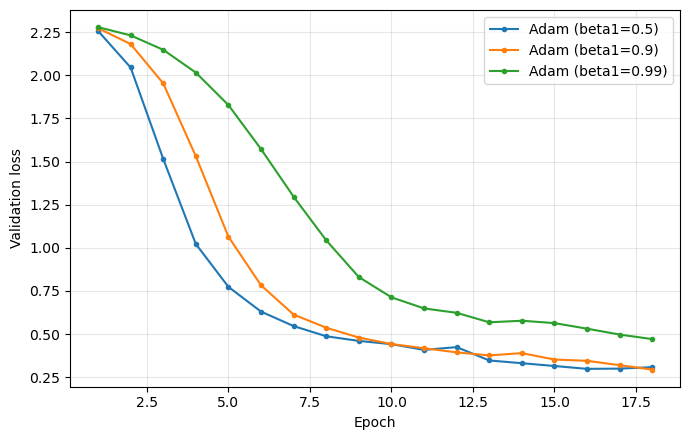

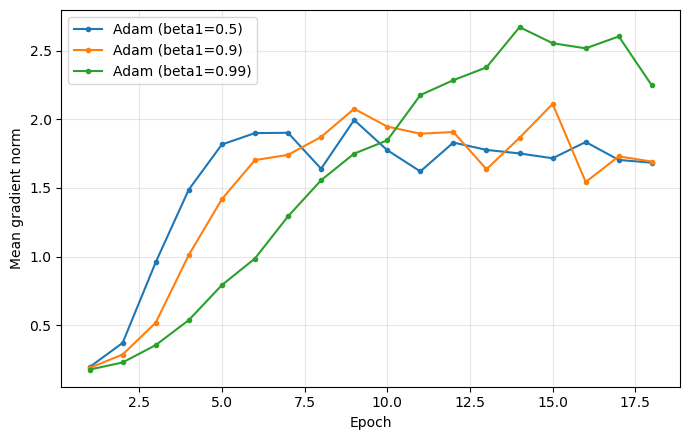

In [6]:
# %% 6. 一阶矩系数 beta1 敏感性
# beta1 越大，历史梯度的记忆越强；过大时模型对方向改变的响应可能滞后。
beta1_results = []
for beta1 in [0.5, 0.9, 0.99]:
    beta1_results.append(
        train_experiment(
            f"Adam (beta1={beta1:g})",
            lambda p, beta1=beta1: torch.optim.Adam(p, lr=1e-3, betas=(beta1, 0.999)),
        )
    )
plot_histories(beta1_results, "val_loss", "Validation loss", "06_beta1_loss.png")
plot_histories(beta1_results, "grad_norm", "Mean gradient norm", "07_beta1_gradient_norm.png")


Adam (beta2=0.9)       测试损失=0.2466, 测试准确率=0.9111
Adam (beta2=0.999)     测试损失=0.1492, 测试准确率=0.9556
Adam (beta2=0.9999)    测试损失=0.1607, 测试准确率=0.9593


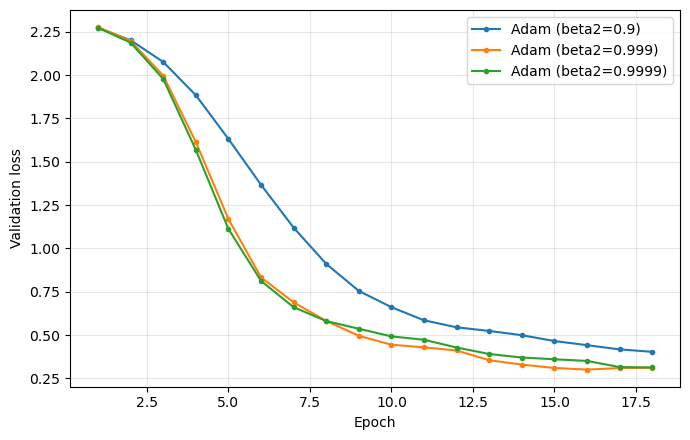

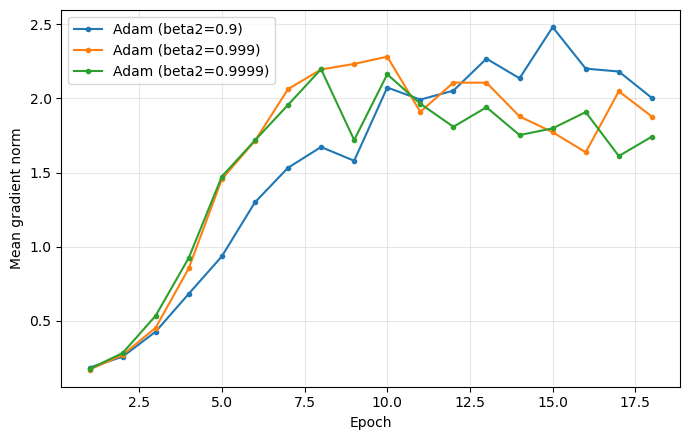

In [7]:
# %% 7. 二阶矩系数 beta2 敏感性
# beta2 控制平方梯度的平滑程度，影响每个参数的自适应有效步长。
beta2_results = []
for beta2 in [0.9, 0.999, 0.9999]:
    beta2_results.append(
        train_experiment(
            f"Adam (beta2={beta2:g})",
            lambda p, beta2=beta2: torch.optim.Adam(p, lr=1e-3, betas=(0.9, beta2)),
        )
    )
plot_histories(beta2_results, "val_loss", "Validation loss", "08_beta2_loss.png")
plot_histories(beta2_results, "grad_norm", "Mean gradient norm", "09_beta2_gradient_norm.png")

Adam (eps=1e-08)       测试损失=0.1750, 测试准确率=0.9481
Adam (eps=1e-05)       测试损失=0.1542, 测试准确率=0.9593
Adam (eps=0.001)       测试损失=0.2223, 测试准确率=0.9259


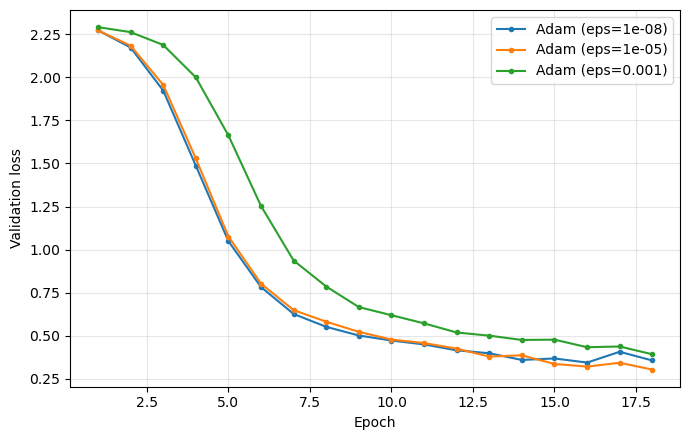

In [8]:
# %% 8. 稳定项 epsilon 的补充实验
# epsilon 位于分母 sqrt(v_hat) + epsilon 中，可避免除零或极小分母造成的过大更新。
epsilon_results = []
for eps in [1e-8, 1e-5, 1e-3]:
    epsilon_results.append(
        train_experiment(
            f"Adam (eps={eps:g})",
            lambda p, eps=eps: torch.optim.Adam(p, lr=1e-3, eps=eps),
        )
    )
plot_histories(epsilon_results, "val_loss", "Validation loss", "10_epsilon_loss.png")


In [9]:
# %% 9. 汇总结果并导出表格
all_results = baseline_results + lr_results + beta1_results + beta2_results + epsilon_results
summary = pd.DataFrame(
    {
        "experiment": [result["label"] for result in all_results],
        "final_val_loss": [result["history"]["val_loss"].iloc[-1] for result in all_results],
        "final_val_acc": [result["history"]["val_acc"].iloc[-1] for result in all_results],
        "test_loss": [result["test_loss"] for result in all_results],
        "test_acc": [result["test_acc"] for result in all_results],
        "final_grad_norm": [result["history"]["grad_norm"].iloc[-1] for result in all_results],
    }
).sort_values("test_acc", ascending=False)
summary.to_csv(DATA_DIR / "初版实验汇总.csv", index=False, encoding="utf-8-sig")
print("\n实验汇总：")
print(summary.to_string(index=False, float_format=lambda x: f"{x:.4f}"))


实验汇总：
         experiment  final_val_loss  final_val_acc  test_loss  test_acc  final_grad_norm
     Adam (lr=0.01)          0.2186         0.9407     0.0841    0.9778           0.4830
      SGD (lr=0.02)          0.2678         0.9185     0.1129    0.9630           0.9524
   Adam (beta1=0.9)          0.2944         0.9074     0.1411    0.9630           1.6918
    Adam (lr=0.001)          0.3125         0.9074     0.1584    0.9593           1.6624
Adam (beta2=0.9999)          0.3127         0.8963     0.1607    0.9593           1.7422
   Adam (eps=1e-05)          0.3041         0.8889     0.1542    0.9593           1.5830
   Adam (beta1=0.5)          0.3085         0.8926     0.1593    0.9556           1.6838
 Adam (beta2=0.999)          0.3112         0.8926     0.1492    0.9556           1.8774
    Adam (lr=0.001)          0.3080         0.8815     0.1689    0.9519           1.9101
   Adam (eps=1e-08)          0.3569         0.8889     0.1750    0.9481           1.7841
  Adam (beta1=

## 报告分析提示


1. 学习率 alpha 决定全局更新幅度。过小导致迭代缓慢，过大可能破坏下降性并引发震荡。
2. beta1 是梯度一阶矩的指数滑动平均系数，体现了动量和方向平滑。
3. beta2 是梯度平方二阶矩的指数滑动平均系数，决定自适应步长的平滑程度。
4. epsilon 防止分母过小，从而避免数值不稳定；在本实验的 FP32 常规训练下差异可能不显著，这本身也是合理结论。
5. 讨论时应区分“训练收敛更快”和“泛化性能更好”：两者不必然完全一致。
